# Kiểm tra dữ liệu — TV1
Chuyển 5 bước đã chạy vào đây hoặc gọi src.data sau khi hoàn thành. Chưa có data/output trong notebook khung.

In [1]:


import torch
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# Chuyển ảnh thành tensor để PyTorch xử lý.
transform = transforms.ToTensor()

# Tập dùng cho huấn luyện và tách validation.
full_train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Tập kiểm tra cuối cùng.
test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

class_names = full_train_dataset.classes

print("Số ảnh train ban đầu:", len(full_train_dataset))
print("Số ảnh test:", len(test_dataset))
print("Tên các lớp:", class_names)


100%|██████████| 26.4M/26.4M [00:05<00:00, 4.85MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 130kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 2.04MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.1MB/s]

Số ảnh train ban đầu: 60000
Số ảnh test: 10000
Tên các lớp: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


TEST 1 ẢNH VÀ 1 NHÃN BẤT KÌ XEM DỮ LIỆU ĐÃ CHẠY ĐC CHƯA


Kích thước ảnh: torch.Size([1, 28, 28])
Kiểu dữ liệu ảnh: torch.float32
Pixel nhỏ nhất: 0.0
Pixel lớn nhất: 1.0
Nhãn số: 9
Tên lớp: Ankle boot


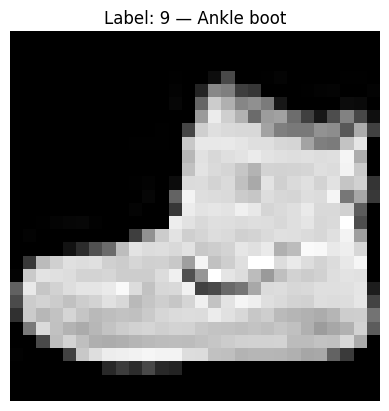

In [2]:
image, label = full_train_dataset[0]

print("Kích thước ảnh:", image.shape)
print("Kiểu dữ liệu ảnh:", image.dtype)
print("Pixel nhỏ nhất:", image.min().item())
print("Pixel lớn nhất:", image.max().item())
print("Nhãn số:", label)
print("Tên lớp:", class_names[label])

plt.imshow(image.squeeze(0), cmap="gray")
plt.title(f"Label: {label} — {class_names[label]}")
plt.axis("off")
plt.show()

Xem nhiều ảnh để hiểu data

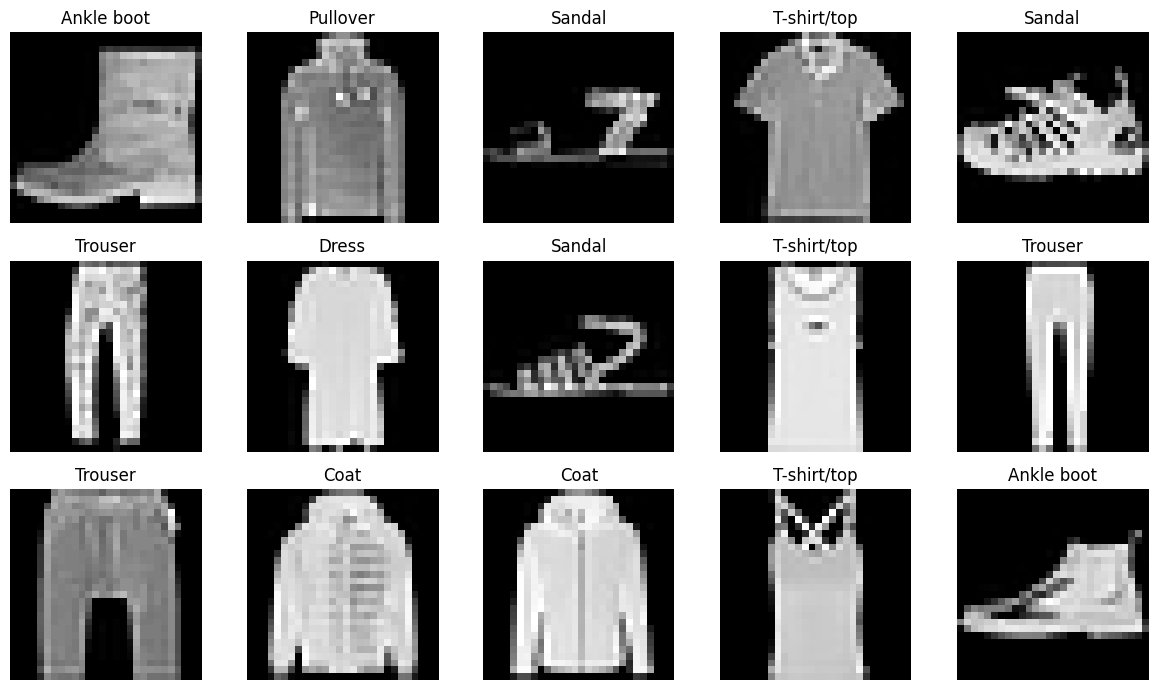

In [3]:
fig, axes = plt.subplots(3, 5, figsize=(12, 7))

generator = torch.Generator().manual_seed(42)
indices = torch.randperm(
    len(full_train_dataset),
    generator=generator
)[:15]

for ax, index in zip(axes.flat, indices.tolist()):
    image, label = full_train_dataset[index]

    ax.imshow(image.squeeze(0), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

Thử chia train và test ( lưu ý đây chỉ là thực nghiệm)

In [4]:
train_dataset, val_dataset = random_split(
    full_train_dataset,
    [54000, 6000],
    generator=torch.Generator().manual_seed(42)
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 54000
Validation: 6000
Test: 10000


Gom ảnh thành batch bằng DataLoader


In [5]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(42)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

images, labels = next(iter(train_loader))

print("Kích thước batch ảnh:", images.shape)
print("Kích thước batch nhãn:", labels.shape)
print("Kiểu nhãn:", labels.dtype)

Kích thước batch ảnh: torch.Size([64, 1, 28, 28])
Kích thước batch nhãn: torch.Size([64])
Kiểu nhãn: torch.int64
